In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from glob import glob

In [2]:
import os
import numpy as np
import librosa
import cv2
from glob import glob

# Function to augment audio data
def augment_audio(audio, sr):
    augmented_data = []
    
    # Time stretching
    stretched = librosa.effects.time_stretch(audio, rate=np.random.uniform(0.8, 1.2))
    augmented_data.append(stretched)
    
    # Pitch shifting
    pitched = librosa.effects.pitch_shift(y=audio, sr=sr, n_steps=np.random.uniform(-2, 2))
    augmented_data.append(pitched)
    
    # Adding noise
    noise = np.random.randn(len(audio))
    noisy_audio = audio + 0.005 * noise
    augmented_data.append(noisy_audio)
    
    return augmented_data

# Function to convert mel spectrogram to RGB (3-channel)
def mel_to_rgb(mel_spec_db):
    mel_spec_db_norm = (mel_spec_db - mel_spec_db.min()) / (mel_spec_db.max() - mel_spec_db.min())
    mel_spec_db_norm = (mel_spec_db_norm * 255).astype(np.uint8)
    mel_resized = cv2.resize(mel_spec_db_norm, (224, 224))
    mel_rgb = np.stack((mel_resized,) * 3, axis=-1)  # Convert to 3-channel RGB
    return mel_rgb

# Function to load and preprocess .wav files with data augmentation
def load_wav_and_annotations_with_augmentation(file_paths, annotation_path):
    X, y = [], []
    for file_path in file_paths:
        file_name = os.path.basename(file_path)
        annotation_file = os.path.join(annotation_path, file_name.replace('.wav', '.txt'))
        
        # Load .wav file
        audio, sr = librosa.load(file_path, sr=None)
        
        # Generate original mel spectrogram
        mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        mel_rgb = mel_to_rgb(mel_spec_db)
        X.append(mel_rgb)
        
        # Load corresponding annotations
        crackle_present = False
        wheeze_present = False
        with open(annotation_file, 'r') as f:
            for line in f:
                data = line.strip().split('\t')
                if int(data[2]) == 1:
                    crackle_present = True
                if int(data[3]) == 1:
                    wheeze_present = True
        
        # Assign label
        if crackle_present:
            label = 'crackles'
        elif wheeze_present:
            label = 'wheezes'
        else:
            label = 'normal'
        
        y.append(label)
        
        # Apply augmentations
        augmented_audios = augment_audio(audio, sr)
        for augmented_audio in augmented_audios:
            mel_spec_aug = librosa.feature.melspectrogram(y=augmented_audio, sr=sr)
            mel_spec_db_aug = librosa.power_to_db(mel_spec_aug, ref=np.max)
            mel_rgb_aug = mel_to_rgb(mel_spec_db_aug)
            X.append(mel_rgb_aug)
            y.append(label)

    # Convert to numpy array
    X = np.array(X)
    y = np.array(y)
    
    return X, y

# Example: Load the dataset
wav_file_paths = glob('ICBHI_final_database/wav_files/**/*.wav', recursive=True)
annotation_path = 'ICBHI_final_database/annotations/'

X, y = load_wav_and_annotations_with_augmentation(wav_file_paths, annotation_path)

In [3]:
# Encode labels

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

# Encode labels if not already done
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)  # Converts labels to integers
y_categorical = to_categorical(y_encoded, num_classes=3)  # Converts to one-hot encoding (for 3 classes)

# Proceed with the train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y_categorical, test_size=0.2, random_state=42)

# Check the shape after splitting
print("X_train shape before reshaping:", X_train.shape)
print("X_test shape before reshaping:", X_test.shape)

# Ensure correct reshaping for CNN (add channel dimension)
# Since X is already RGB, we expect it to be (num_samples, 128, 128, 3)
if X_train.ndim == 3:  # This should not occur if X is RGB
    raise ValueError("X_train should have 4 dimensions for RGB data")
elif X_train.ndim == 4:
    # No need to reshape, but you can check the shape
    if X_train.shape[3] != 3:
        raise ValueError("X_train must have 3 channels for RGB data")

print("Training data shape for ResNet:", X_train.shape)
print("Test data shape for ResNet:", X_test.shape)



X_train shape before reshaping: (2480, 224, 224, 3)
X_test shape before reshaping: (620, 224, 224, 3)
Training data shape for ResNet: (2480, 224, 224, 3)
Test data shape for ResNet: (620, 224, 224, 3)


In [29]:
X, y = load_wav_and_annotations_with_augmentation(wav_file_paths, annotation_path)
print(f"Number of spectrograms (X): {len(X)}")
print(f"Number of labels (y): {len(y)}")

Number of spectrograms (X): 3100
Number of labels (y): 3100


In [4]:
from tensorflow.keras.applications import ResNet152
from tensorflow.keras import layers, models, optimizers

# Load ResNet152 without the top layers
base_model = ResNet152(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base model layers
base_model.trainable = False

# Build your model on top of ResNet52
def create_transfer_model():
    model = models.Sequential()

    # Add ResNet152 as the feature extractor
    model.add(base_model)

    # Add global pooling
    model.add(layers.GlobalAveragePooling2D())

    # Dense layer to learn new features
    model.add(layers.Dense(224, activation='relu'))
    model.add(layers.Dropout(0.5))

    # Output layer for 3 classes
    model.add(layers.Dense(3, activation='softmax'))

    # Compile the model
    model.compile(optimizer=optimizers.Adam(learning_rate=0.0001),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    return model

# Create and summarize the model
transfer_model = create_transfer_model()
transfer_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet152 (Functional)          │ (None, 7, 7, 2048)     │    58,370,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 224)            │       458,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 224)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           675 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,830,595 (224.42 MB)

 Trainable params: 459,651 (1.75 MB)

 Non-trainable params: 58,370,944 (222.67 MB)

In [7]:
# OPTIONAL: Fine-tune some layers of ResNet after initial training
def fine_tune_transfer_model(model, base_model, num_fine_tune_layers=50):
    # Unfreeze the top layers of ResNet for fine-tuning
    base_model.trainable = True
    
    # Freeze all layers except the last `num_fine_tune_layers` layers
    for layer in base_model.layers[:-num_fine_tune_layers]:
        layer.trainable = False

    # Recompile the model with a lower learning rate for fine-tuning
    model.compile(optimizer=optimizers.Adam(learning_rate=1e-5),  # Even lower learning rate for fine-tuning
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    return model

# Optionally fine-tune the model
transfer_model = fine_tune_transfer_model(transfer_model, base_model)

In [8]:
# Unfreeze the top 50 layers for fine-tuning
transfer_model = fine_tune_transfer_model(transfer_model, base_model, num_fine_tune_layers=50)

# Fine-tune the model with a lower learning rate
fine_tune_history = transfer_model.fit(X_train, y_train, epochs=10, batch_size=16, validation_data=(X_test, y_test))

Epoch 1/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 731s 4s/step - accuracy: 0.5504 - loss: 1.1704 - val_accuracy: 0.6661 - val_loss: 0.7550
Epoch 2/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 667s 4s/step - accuracy: 0.6977 - loss: 0.6701 - val_accuracy: 0.7500 - val_loss: 0.6190
Epoch 3/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 626s 4s/step - accuracy: 0.7909 - loss: 0.5319 - val_accuracy: 0.7806 - val_loss: 0.5391
Epoch 4/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 633s 4s/step - accuracy: 0.8798 - loss: 0.3682 - val_accuracy: 0.8194 - val_loss: 0.4702
Epoch 5/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 622s 4s/step - accuracy: 0.9060 - loss: 0.2828 - val_accuracy: 0.8274 - val_loss: 0.4266
Epoch 6/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 615s 4s/step - accuracy: 0.9385 - loss: 0.1958 - val_accuracy: 0.8742 - val_loss: 0.3557
Epoch 7/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 614s 4s/step - accuracy: 0.9578 - loss: 0.1413 - val_accuracy: 0.8742 - val_loss: 0.3341
Epoch 8/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 614s 4s/step - accuracy: 0.9804 - loss: 0.0937 - val_accu

In [5]:
# Train the model
history = transfer_model.fit(X_train, y_train, epochs=10, batch_size=16, validation_data=(X_test, y_test))

Epoch 1/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 815s 5s/step - accuracy: 0.5135 - loss: 1.1163 - val_accuracy: 0.6129 - val_loss: 0.8532
Epoch 2/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 702s 5s/step - accuracy: 0.5874 - loss: 0.8976 - val_accuracy: 0.6177 - val_loss: 0.8310
Epoch 3/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 734s 5s/step - accuracy: 0.6182 - loss: 0.8656 - val_accuracy: 0.6339 - val_loss: 0.8229
Epoch 4/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 730s 5s/step - accuracy: 0.6415 - loss: 0.7987 - val_accuracy: 0.6468 - val_loss: 0.8034
Epoch 5/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 742s 5s/step - accuracy: 0.6518 - loss: 0.7931 - val_accuracy: 0.6484 - val_loss: 0.7859
Epoch 6/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 806s 5s/step - accuracy: 0.6815 - loss: 0.7595 - val_accuracy: 0.6597 - val_loss: 0.7684
Epoch 7/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 778s 5s/step - accuracy: 0.6879 - loss: 0.7323 - val_accuracy: 0.6871 - val_loss: 0.7707
Epoch 8/10
155/155 ━━━━━━━━━━━━━━━━━━━━ 743s 5s/step - accuracy: 0.6798 - loss: 0.7197 - val_accu

20/20 ━━━━━━━━━━━━━━━━━━━━ 95s 5s/step


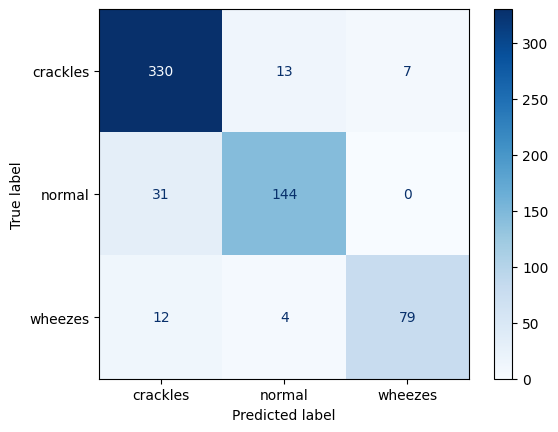

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Make predictions on the test set
y_pred = transfer_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Generate confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.show()


In [11]:
#### F1 score
from sklearn.metrics import classification_report, confusion_matrix

# Make predictions on the test set
y_pred = transfer_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Print classification report (F1-score, precision, recall)
report = classification_report(y_true_classes, y_pred_classes, target_names=label_encoder.classes_)
print(report)

# Confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
print("Confusion Matrix:")
print(cm)

20/20 ━━━━━━━━━━━━━━━━━━━━ 96s 5s/step
              precision    recall  f1-score   support

    crackles       0.88      0.94      0.91       350
      normal       0.89      0.82      0.86       175
     wheezes       0.92      0.83      0.87        95

    accuracy                           0.89       620
   macro avg       0.90      0.87      0.88       620
weighted avg       0.89      0.89      0.89       620

Confusion Matrix:
[[330  13   7]
 [ 31 144   0]
 [ 12   4  79]]


In [ ]:
# to check labels
print(np.unique(y))


['crackles' 'normal' 'wheezes']


In [13]:
# Check the distribution of labels
unique, counts = np.unique(y, return_counts=True)
print(f"Label distribution: {dict(zip(unique, counts))}")


Label distribution: {np.str_('crackles'): np.int64(1776), np.str_('normal'): np.int64(840), np.str_('wheezes'): np.int64(484)}


In [14]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Generate the confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

# Define labels for clarity
class_names = ["Normal", "Crackles", "Wheezes"]

# Initialize lists to store sensitivity and specificity for each class
sensitivity = []
specificity = []

# Calculate sensitivity and specificity for each class
for i, class_name in enumerate(class_names):
    TP = cm[i, i]  # True Positives for class i
    FN = np.sum(cm[i, :]) - TP  # False Negatives for class i
    FP = np.sum(cm[:, i]) - TP  # False Positives for class i
    TN = np.sum(cm) - (TP + FN + FP)  # True Negatives for class i
    
    # Sensitivity (Recall)
    class_sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0
    sensitivity.append(class_sensitivity)
    
    # Specificity
    class_specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    specificity.append(class_specificity)
    
    print(f"{class_name} - Sensitivity: {class_sensitivity:.2f}, Specificity: {class_specificity:.2f}")

# Calculate the average score (average of sensitivity and specificity for each class)
average_sensitivity = np.mean(sensitivity)
average_specificity = np.mean(specificity)
score = (average_sensitivity + average_specificity) / 2

print(f"\nAverage Sensitivity: {average_sensitivity:.2f}")
print(f"Average Specificity: {average_specificity:.2f}")
print(f"Score (Average of Sensitivity and Specificity): {score:.2f}")


Normal - Sensitivity: 0.94, Specificity: 0.84
Crackles - Sensitivity: 0.82, Specificity: 0.96
Wheezes - Sensitivity: 0.83, Specificity: 0.99

Average Sensitivity: 0.87
Average Specificity: 0.93
Score (Average of Sensitivity and Specificity): 0.90


In [15]:
# Evaluate the model
test_loss, test_accuracy = transfer_model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


20/20 ━━━━━━━━━━━━━━━━━━━━ 106s 5s/step - accuracy: 0.8763 - loss: 0.3586
Test Accuracy: 89.19%


In [16]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Make predictions on the test set
y_pred = transfer_model.predict(X_test)

# Convert predicted probabilities to class predictions using argmax
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Print classification report (F1-score, precision, recall)
target_names = ["Normal", "Crackles", "Wheezes"]  # Update this according to your class labels
print("Classification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=target_names, zero_division=0))

# Confusion matrix
print("Confusion Matrix:")
cm = confusion_matrix(y_true_classes, y_pred_classes)
print(cm)

# Analyze how many samples were predicted for each category
print("\nNumber of predicted 'Normal':", np.sum(y_pred_classes == 0))
print("Number of predicted 'Crackles':", np.sum(y_pred_classes == 1))
print("Number of predicted 'Wheezes':", np.sum(y_pred_classes == 2))

print("\nNumber of actual 'Normal':", np.sum(y_true_classes == 0))
print("Number of actual 'Crackles':", np.sum(y_true_classes == 1))
print("Number of actual 'Wheezes':", np.sum(y_true_classes == 2))


20/20 ━━━━━━━━━━━━━━━━━━━━ 84s 4s/step
Classification Report:
              precision    recall  f1-score   support

      Normal       0.88      0.94      0.91       350
    Crackles       0.89      0.82      0.86       175
     Wheezes       0.92      0.83      0.87        95

    accuracy                           0.89       620
   macro avg       0.90      0.87      0.88       620
weighted avg       0.89      0.89      0.89       620

Confusion Matrix:
[[330  13   7]
 [ 31 144   0]
 [ 12   4  79]]

Number of predicted 'Normal': 373
Number of predicted 'Crackles': 161
Number of predicted 'Wheezes': 86

Number of actual 'Normal': 350
Number of actual 'Crackles': 175
Number of actual 'Wheezes': 95


In [20]:
# Define the function first
import os
import numpy as np
import librosa
import cv2

def predict_lung_sounds(model, file_paths, label_encoder):
    def mel_to_rgb(mel_spec_db):
        mel_spec_db_norm = (mel_spec_db - mel_spec_db.min()) / (mel_spec_db.max() - mel_spec_db.min())
        mel_spec_db_norm = (mel_spec_db_norm * 255).astype(np.uint8)
        mel_resized = cv2.resize(mel_spec_db_norm, (224, 224))
        mel_rgb = np.stack((mel_resized,) * 3, axis=-1)
        return mel_rgb

    for file_path in file_paths:
        # Load .wav file
        audio, sr = librosa.load(file_path, sr=None)
        
        # Generate mel-spectrogram
        mel_spec = librosa.feature.melspectrogram(y=audio, sr=sr)
        mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
        
        # Convert to RGB format compatible with ResNet
        mel_rgb = mel_to_rgb(mel_spec_db)
        
        # Add batch dimension
        mel_rgb_input = np.expand_dims(mel_rgb, axis=0)
        
        # Predict using the model
        prediction = model.predict(mel_rgb_input)
        predicted_class = np.argmax(prediction, axis=1)
        predicted_label = label_encoder.inverse_transform(predicted_class)
        
        print(f"Prediction for {os.path.basename(file_path)}: {predicted_label[0]}")

# Example of how you provide the .wav file paths
left_lung_files = [
    r'C:\Users\dell\Documents\OxySteth\ICBHI_final_database\wav_files\left_lung\101_1b1_Al_sc_Meditron.wav',
    r'C:\Users\dell\Documents\OxySteth\personalTEST\BP1_Asthma,I E W,P L L,70,M.wav',
    r'C:\Users\dell\Documents\OxySteth\personalTEST\223_1b1_Al_sc_Meditron.wav'
]

right_lung_files = [
    r'C:\Users\dell\Documents\OxySteth\ICBHI_final_database\wav_files\right_lung\104_1b1_Pr_sc_Litt3200.wav',
    r'C:\Users\dell\Documents\OxySteth\ICBHI_final_database\wav_files\left_lung\107_2b5_Ll_mc_AKGC417L.wav',
    r'C:\Users\dell\Documents\OxySteth\personalTEST\223_1b1_Lr_sc_Meditron.wav'
]

# Now call the function
print("Left lung predictions:")
predict_lung_sounds(transfer_model, left_lung_files, label_encoder)

print("\nRight lung predictions:")
predict_lung_sounds(transfer_model, right_lung_files, label_encoder)

Left lung predictions:
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Prediction for 101_1b1_Al_sc_Meditron.wav: normal
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step
Prediction for BP1_Asthma,I E W,P L L,70,M.wav: wheezes
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step
Prediction for 223_1b1_Al_sc_Meditron.wav: normal

Right lung predictions:
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
Prediction for 104_1b1_Pr_sc_Litt3200.wav: normal
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step
Prediction for 107_2b5_Ll_mc_AKGC417L.wav: crackles
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step
Prediction for 223_1b1_Lr_sc_Meditron.wav: crackles


In [18]:
# Save your trained model
transfer_model.save('lung_sound_model1.h5')

In [19]:
import pickle

# Save your label encoder
with open('label_encoder1.pkl', 'wb') as f:
    pickle.dump(label_encoder, f)